Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


First Five Records:
   petal length (cm)  petal width (cm)
0                1.4               0.2
1                1.4               0.2
2                1.3               0.2
3                1.5               0.2
4                1.4               0.2

Dataset Shape: (150, 2)


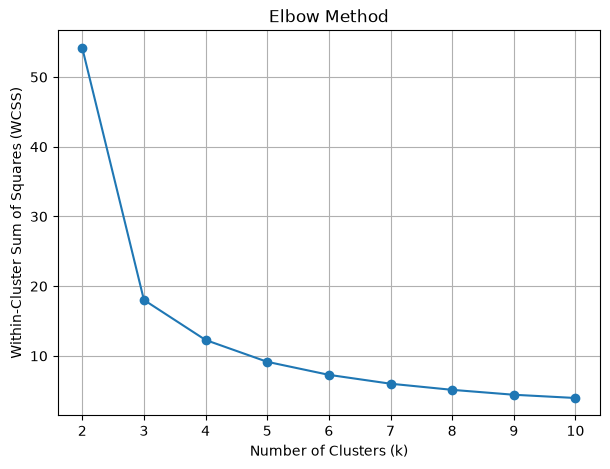


Silhouette Scores:
k = 2 Score = 0.7434
k = 3 Score = 0.6741
k = 4 Score = 0.5988
k = 5 Score = 0.5736
k = 6 Score = 0.5818
k = 7 Score = 0.5728
k = 8 Score = 0.5898
k = 9 Score = 0.4619
k = 10 Score = 0.4681

Optimal Number of Clusters: 2

Clustered Dataset:
   petal length (cm)  petal width (cm)  Cluster
0                1.4               0.2        1
1                1.4               0.2        1
2                1.3               0.2        1
3                1.5               0.2        1
4                1.4               0.2        1

Cluster Sizes:
Cluster
0    100
1     50
Name: count, dtype: int64

Cluster Centroids:
   petal length (cm)  petal width (cm)
0              4.906             1.676
1              1.462             0.246


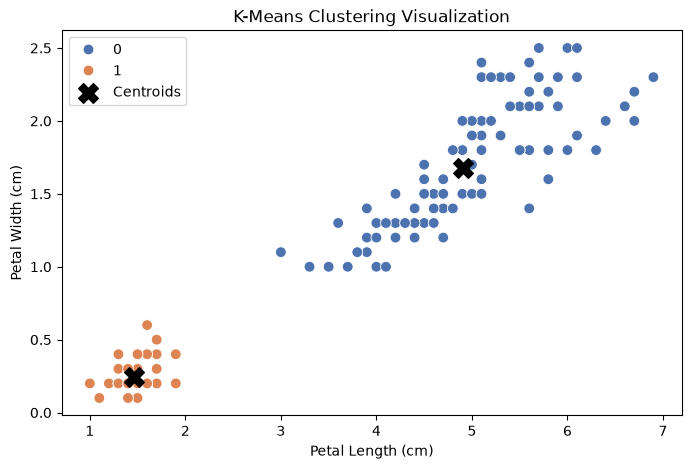

In [2]:

%pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 1: Load the Iris dataset without using species labels
dataset = load_iris()

# Select two numerical features
X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

X = X[["petal length (cm)", "petal width (cm)"]]

print("First Five Records:")
print(X.head())

print("\nDataset Shape:", X.shape)

# Step 2: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3 and 4: Apply K-Means for different values of k
wcss = []
silhouette_scores = {}

for k in range(2, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    wcss.append(model.inertia_)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores[k] = score

# Step 5: Plot the Elbow Curve
plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.grid(True)
plt.show()

# Step 6: Display Silhouette Scores
print("\nSilhouette Scores:")

for k, score in silhouette_scores.items():
    print("k =", k, "Score =", round(score, 4))

# Select k having the highest Silhouette Score
optimal_k = max(silhouette_scores, key=silhouette_scores.get)

print("\nOptimal Number of Clusters:", optimal_k)

# Step 7: Fit the final K-Means model
final_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_model.fit_predict(X_scaled)

# Add cluster labels to the original dataset
clustered_data = X.copy()
clustered_data["Cluster"] = cluster_labels

print("\nClustered Dataset:")
print(clustered_data.head())

print("\nCluster Sizes:")
print(clustered_data["Cluster"].value_counts().sort_index())

# Display cluster centroids in original feature scale
centroids = scaler.inverse_transform(final_model.cluster_centers_)

centroid_data = pd.DataFrame(
    centroids,
    columns=X.columns
)

print("\nCluster Centroids:")
print(centroid_data)

# Visualize the final clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clustered_data,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Cluster",
    palette="deep",
    s=60
)

plt.scatter(
    centroid_data["petal length (cm)"],
    centroid_data["petal width (cm)"],
    marker="X",
    s=200,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering Visualization")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.show()
